#### 선형 회귀( Linear Regression )
- 입력과 출력간의 관계를 선형으로 놓고 알아내는 법
    - 광고비와 매출액의 관계
- 목적 : 최적의 기울기와 절편 구하기
    - 실제값과 예측값의 오차가 최소가 될 수 있도록 구하는게 목적<br>
        : Min(Loss Function)
    - MSE 사용
- 경사하강법 사용

In [1]:
import torch
import matplotlib.pyplot as plt

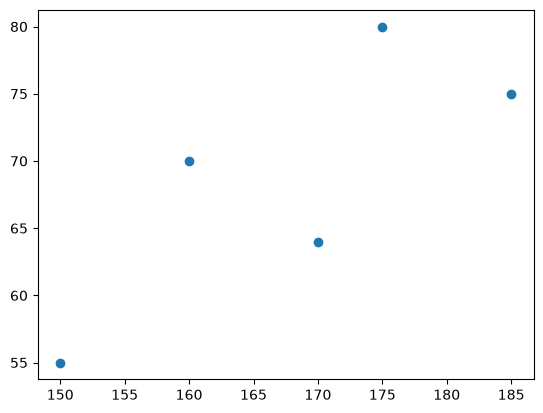

In [2]:
x = torch.tensor([150., 160, 170, 175, 185])
y = torch.tensor([55, 70, 64, 80, 75.])
N = len(x)

plt.plot(x, y, 'o')

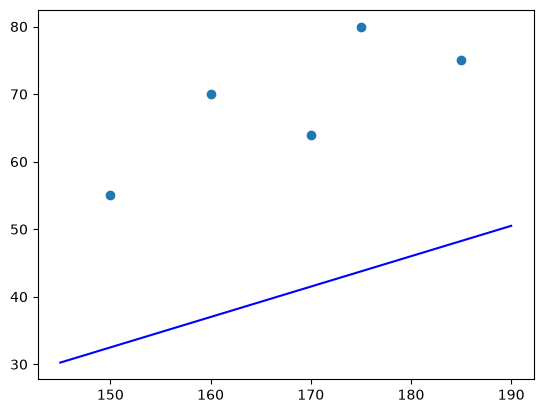

In [3]:
# 처음의 기울기와 절편은 임의로 설정
a = 0.45    # 기울기
b = -35     # 절편

x_plot = torch.linspace(145, 190, 100)
y_plot = a * x_plot + b

plt.figure()
plt.plot(x, y, 'o')             # 실제 키와 몸무게
plt.plot(x_plot, y_plot, 'b')   # 임의로 만든 선형관계

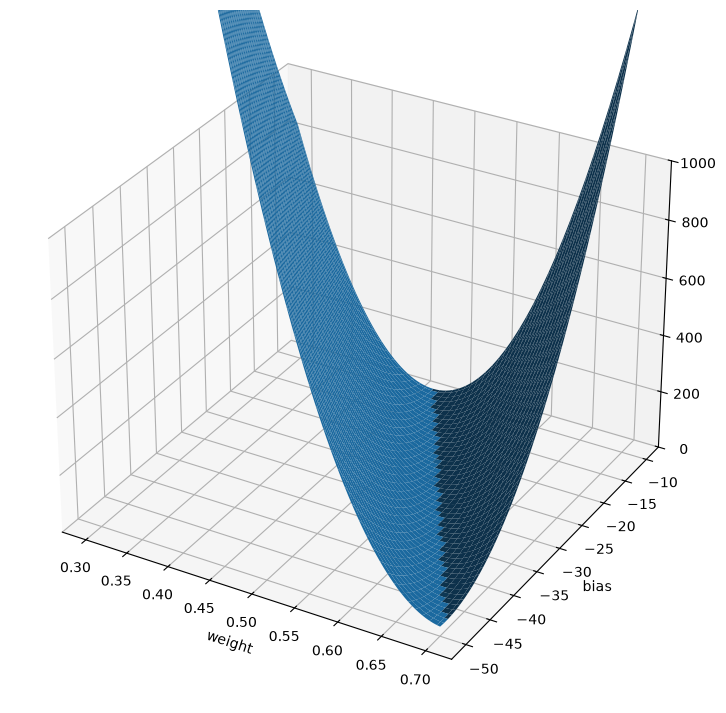

In [4]:
# MSE loss function

a = 0.5 + torch.linspace(-0.2, 0.2, 100)    # 0.3 < a < 0.7 | 기울기 후보군
b = -30 + torch.linspace(-20, 20, 100)      # -50 < b < -10 | 절편 후보군

L = torch.zeros(len(a),len(b))

for i in range(len(a)):
    for j in range(len(b)):
        for n in range(N):  # N = len(x)
            L[i,j] = L[i,j] + (y[n] - (a[i]*x[n] + b[j]))** 2   # 키의 값으로 몸무게를 예측한 값

L = L / N   # MSELoss 값

plt.figure(figsize= [10, 9])
ax = plt.axes(projection= '3d')
A, B = torch.meshgrid(a, b, indexing= 'ij')

ax.plot_surface(A, B, L)
ax.set_xlabel('weight')
ax.set_ylabel('bias')
ax.set_zlim([0,1000])
plt.show()

In [5]:
L

tensor([[4717.8999, 4662.7900, 4608.0068,  ...,  892.4518,  869.0127,
          845.8998],
        [4625.1914, 4570.6304, 4516.3955,  ...,  852.9494,  830.0588,
          807.4945],
        [4533.4097, 4479.3970, 4425.7109,  ...,  814.3732,  792.0311,
          770.0153],
        ...,
        [  37.8939,   35.9905,   34.4135,  ..., 1373.4280, 1403.1949,
         1433.2881],
        [  35.0339,   33.6789,   32.6504,  ..., 1423.7732, 1454.0889,
         1484.7303],
        [  33.1000,   32.2935,   31.8136,  ..., 1475.0457, 1505.9099,
         1537.1000]])

In [6]:
# optimal a b 구하기 (L을 최소로 만드는)
print(torch.min(L))
a_opt = A[L == torch.min(L)]
b_opt = B[L == torch.min(L)]

print(f'optimal a = {a_opt}, optimal b = {b_opt}')

tensor(29.0315)
optimal a = tensor([0.5626]), optimal b = tensor([-25.7576])


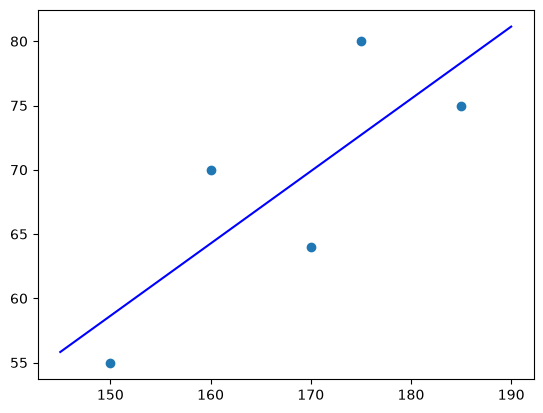

In [7]:
x_plot = torch.linspace(145, 190, 100)
y_plot = a_opt * x_plot + b_opt
plt.plot(x, y, 'o')
plt.plot(x_plot, y_plot, 'b')

plt.show()

#### 경사하강법 Gradient Descent

In [8]:
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)

LR = 3e-6 # 0.000003
# 3e-4 정도로 크면 학습곡선이 발산하는 것을 볼 수 있음
EPOCH = 20
# 1000 정도로 크면 학습곡선이 과적합을 나타냄

loss_history = []

for ep in range(EPOCH):
    y_hat = a * x + b

    loss = 0
    for n in range(N):
        loss += (y[n] - y_hat[n])**2
    loss = loss / N

    loss.backward()

    with torch.no_grad():
        a -= LR * a.grad
        b -= LR * b.grad

    # gradient 초기화
    a.grad = torch.tensor([0.])
    b.grad = torch.tensor([0.])

    # append
    loss_history += [loss.item()]

    # print(f'Epoch : {ep + 1}, train loss : {loss.item():4f}')
    # print(f'weight : {a.item():4f}, bias : {b.item():4f}')

    # x_plot = torch.linspace(145, 190, 100)
    # y_plot = a.detach() * x_plot + b.detach()
    # plt.figure()
    # plt.plot(x, y, 'o')
    # plt.plot(x_plot, y_plot, 'r')
    # plt.title(f'Epoch {ep+1}')
    # plt.show()

    # print('-'*20)

Text(0.5, 1.0, 'Training Loss')

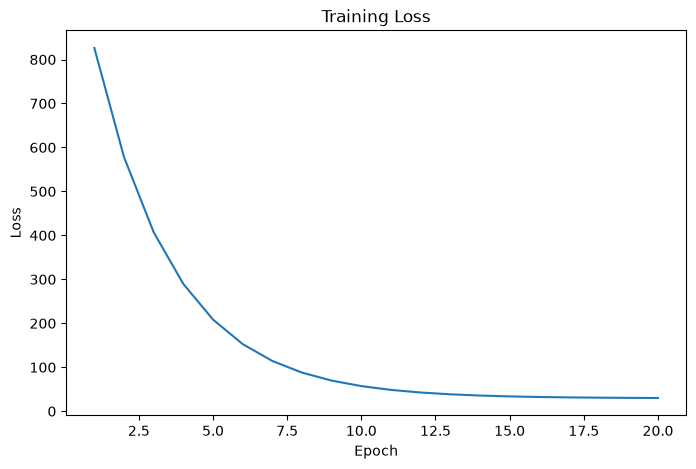

In [9]:
# 학습 곡선
plt.figure(figsize= (8,5))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')

#### 실제 모델 생성
- 초기화 
- 생성 예측값
- loss 계산
- update

In [10]:
# 1단계. 초기화 및 예측값 출력해보기
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)

LR = 3e-6 # 0.000003
EPOCH = 20

loss_history = []

# 초기 값 확인
for ep in range(EPOCH):
    print(x)        # 데이터
    print(a)        # 기울기
    print(b)        # 절편
    y_hat = a * x + b
    print(y_hat)    # 몸무게 예측값
    print()
    break

tensor([150., 160., 170., 175., 185.])
tensor([0.4500], requires_grad=True)
tensor([-35.], requires_grad=True)
tensor([32.5000, 37.0000, 41.5000, 43.7500, 48.2500], grad_fn=<AddBackward0>)



In [11]:
# 2단계. Loss 계산 | 3단계. Update
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)

LR = 3e-6 # 0.000003
EPOCH = 20

loss_history = []

for ep in range(EPOCH):
    print(x)        # 데이터
    print(a)        # 기울기
    print(b)        # 절편
    y_hat = a * x + b
    print(y_hat)    # 몸무게 예측값
    print()

    # Loss 계산
    loss = 0
    for n in range(N):
        loss += (y[n] - y_hat[n])**2
    loss = loss /N

tensor([150., 160., 170., 175., 185.])
tensor([0.4500], requires_grad=True)
tensor([-35.], requires_grad=True)
tensor([32.5000, 37.0000, 41.5000, 43.7500, 48.2500], grad_fn=<AddBackward0>)

tensor([150., 160., 170., 175., 185.])
tensor([0.4500], requires_grad=True)
tensor([-35.], requires_grad=True)
tensor([32.5000, 37.0000, 41.5000, 43.7500, 48.2500], grad_fn=<AddBackward0>)

tensor([150., 160., 170., 175., 185.])
tensor([0.4500], requires_grad=True)
tensor([-35.], requires_grad=True)
tensor([32.5000, 37.0000, 41.5000, 43.7500, 48.2500], grad_fn=<AddBackward0>)

tensor([150., 160., 170., 175., 185.])
tensor([0.4500], requires_grad=True)
tensor([-35.], requires_grad=True)
tensor([32.5000, 37.0000, 41.5000, 43.7500, 48.2500], grad_fn=<AddBackward0>)

tensor([150., 160., 170., 175., 185.])
tensor([0.4500], requires_grad=True)
tensor([-35.], requires_grad=True)
tensor([32.5000, 37.0000, 41.5000, 43.7500, 48.2500], grad_fn=<AddBackward0>)

tensor([150., 160., 170., 175., 185.])
tensor([0.4

In [12]:
from torch import nn, optim

Epoch : 1 Train Loss :826.2250
weight : 0.4785, bias: -34.9998
Epoch : 2 Train Loss :578.0414
weight : 0.5022, bias: -34.9997
Epoch : 3 Train Loss :407.1602
weight : 0.5218, bias: -34.9996
Epoch : 4 Train Loss :289.5042
weight : 0.5381, bias: -34.9995
Epoch : 5 Train Loss :208.4954
weight : 0.5517, bias: -34.9994
Epoch : 6 Train Loss :152.7187
weight : 0.5629, bias: -34.9993
Epoch : 7 Train Loss :114.3153
weight : 0.5722, bias: -34.9993
Epoch : 8 Train Loss :87.8735
weight : 0.5799, bias: -34.9992
Epoch : 9 Train Loss :69.6676
weight : 0.5863, bias: -34.9992
Epoch : 10 Train Loss :57.1324
weight : 0.5917, bias: -34.9992
Epoch : 11 Train Loss :48.5017
weight : 0.5961, bias: -34.9991
Epoch : 12 Train Loss :42.5591
weight : 0.5997, bias: -34.9991
Epoch : 13 Train Loss :38.4676
weight : 0.6028, bias: -34.9991
Epoch : 14 Train Loss :35.6504
weight : 0.6053, bias: -34.9991
Epoch : 15 Train Loss :33.7107
weight : 0.6074, bias: -34.9991
Epoch : 16 Train Loss :32.3752
weight : 0.6091, bias: -34

Text(0.5, 1.0, 'Training Loss')

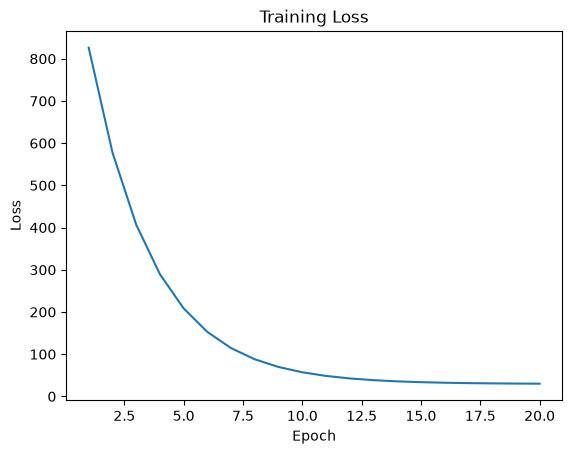

In [13]:
# 실무용 MSE 와 Gradient Descent

x = torch.tensor([150., 160, 170, 175, 185])
y = torch.tensor([55, 70, 64, 80, 75.])

x = x.reshape(-1,1)
y = y.reshape(-1,1)

model = nn.Linear(1,1)  # 초기 w 와 b 를 자동으로 생성

# w 와 b 를 직접 입력하는 법
model.weight.data = torch.tensor([[0.45]])
model.bias.data = torch.tensor([-35.])

LR = 3e-6
EPOCH = 20

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.MSELoss()

loss_history = []
for ep in range(EPOCH):
    # 예측값
    y_hat = model(x)

    # loss
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 출력은 본인 마음대로
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1} Train Loss :{loss.item():.4f}')
    print(f'weight : {model.weight.data.item():.4f}, bias: {model.bias.data.item():.4f}')

    # x_plot = torch.linspace(145, 190, 100)
    # y_plot = model.weight.squeeze().detach()* x_plot + model.bias.squeeze().detach()
    # plt.figure()
    # plt.plot(x,y,'o')
    # plt.plot(x_plot, y_plot, 'r')
    # plt.title(f'Epoch {ep+1}')
    # plt.show()

# 학습 곡선
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')

Epoch : 1 Train Loss :826.2250
weight : 0.4785, bias: -34.9998
Epoch : 2 Train Loss :578.0414
weight : 0.5022, bias: -34.9997
Epoch : 3 Train Loss :407.1602
weight : 0.5218, bias: -34.9996
Epoch : 4 Train Loss :289.5042
weight : 0.5381, bias: -34.9995
Epoch : 5 Train Loss :208.4954
weight : 0.5517, bias: -34.9994
Epoch : 6 Train Loss :152.7187
weight : 0.5629, bias: -34.9993
Epoch : 7 Train Loss :114.3153
weight : 0.5722, bias: -34.9993
Epoch : 8 Train Loss :87.8735
weight : 0.5799, bias: -34.9992
Epoch : 9 Train Loss :69.6676
weight : 0.5863, bias: -34.9992
Epoch : 10 Train Loss :57.1324
weight : 0.5917, bias: -34.9992
Epoch : 11 Train Loss :48.5017
weight : 0.5961, bias: -34.9991
Epoch : 12 Train Loss :42.5591
weight : 0.5997, bias: -34.9991
Epoch : 13 Train Loss :38.4676
weight : 0.6028, bias: -34.9991
Epoch : 14 Train Loss :35.6504
weight : 0.6053, bias: -34.9991
Epoch : 15 Train Loss :33.7107
weight : 0.6074, bias: -34.9991
Epoch : 16 Train Loss :32.3752
weight : 0.6091, bias: -34

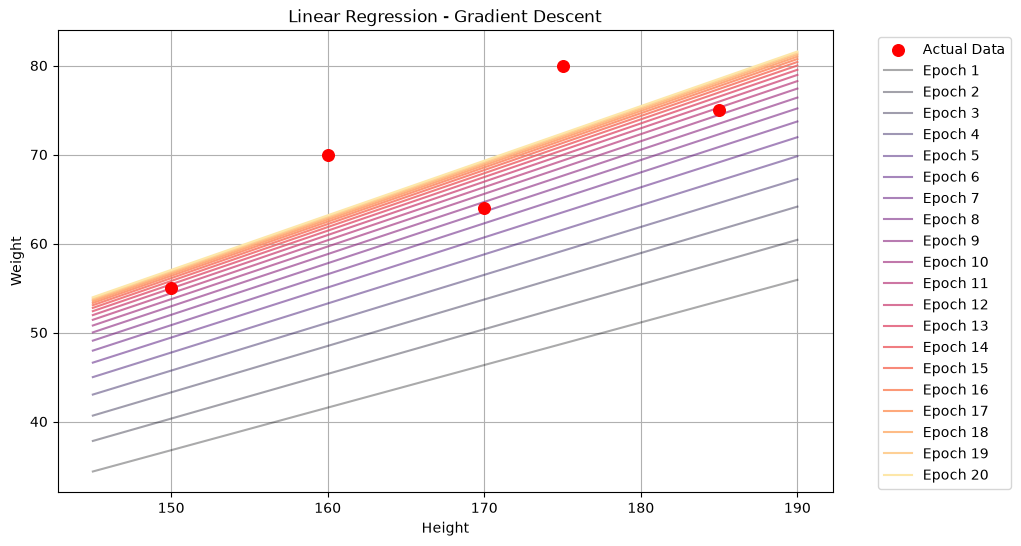

In [14]:
# 하나의 그래프에 모든 예측 나타내기
x = torch.tensor([150., 160, 170, 175, 185])
y = torch.tensor([55, 70, 64, 80, 75.])

x = x.reshape(-1,1)
y = y.reshape(-1,1)

model = nn.Linear(1,1)  # 초기 w 와 b 를 자동으로 생성

# w 와 b 를 직접 입력하는 법
model.weight.data = torch.tensor([[0.45]])
model.bias.data = torch.tensor([-35.])

LR = 3e-6
EPOCH = 20

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.MSELoss()

# 그래프를 학습 루프 밖에서 생성
plt.figure(figsize=(10, 6))

# 실제 데이터 표시
plt.scatter(x.numpy(), y.numpy(),
            color='red', s=70, label='Actual Data', zorder=5)

x_plot = torch.linspace(145, 190, 100).reshape(-1, 1)

for ep in range(EPOCH):
    # 예측값
    y_hat = model(x)

    # loss
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 출력은 본인 마음대로
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1} Train Loss :{loss.item():.4f}')
    print(f'weight : {model.weight.data.item():.4f}, bias: {model.bias.data.item():.4f}')

    # 현재 Epoch의 회귀직선 계산
    with torch.no_grad():
        y_plot = model(x_plot)

    # Epoch별 회귀직선을 같은 그래프에 추가
    plt.plot(
        x_plot.numpy(),
        y_plot.numpy(),
        alpha=0.3 + 0.7 * (ep + 1) / EPOCH,
        color=plt.cm.magma(ep / EPOCH),
        label=f'Epoch {ep+1}'
    )

plt.xlabel('Height')
plt.ylabel('Weight')
plt.title('Linear Regression - Gradient Descent')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

    # x_plot = torch.linspace(145, 190, 100)
    # y_plot = model.weight.squeeze().detach()* x_plot + model.bias.squeeze().detach()
    # plt.figure()
    # plt.plot(x,y,'o')
    # plt.plot(x_plot, y_plot, 'r')
    # plt.title(f'Epoch {ep+1}')
    # plt.show()